# 04 · Class-Imbalance Handling

**Project:** An Intelligent Traffic Violation Management System for Sri Lanka with ML-Based Dynamic Severity Assessment and Driver Risk Scoring
**Author:** Damma Monnankulama (20211211 / W1899305)

**Why this notebook exists.** Notebook 03 showed that without imbalance handling every model collapses towards "always *Slight*". Test accuracy is about 0.85 (the majority rate) and **fatal recall is about 0** (Research Challenge 1, Proposal §3.13).

**Goals**
1. **Section A:** compare imbalance techniques and find the best one for each model.
2. **Section B:** with the best technique, re-test which features are really needed. This finishes the `Lanes_or_Medians` / `Road_alignment` question from notebook 03.
3. **Section C:** drop-one-feature analysis, now that the models actually use the minority classes.
4. **Section D:** record the decision (final feature set + technique per model) for the next notebooks.

**Controlled-experiment design.** Everything except the imbalance technique is kept **identical to notebook 03**: the same 3-class target, the same 80/20 stratified split, the same 5 seeds and the same model hyperparameters (`MODEL_PARAMS`). Any change in results is therefore caused by the imbalance technique. Hyperparameter tuning comes later (notebook 05), using cross-validation on the training data only.

### The techniques
| Technique | What it does | Applies to |
|---|---|---|
| `none` | No correction (= notebook 03) | all models |
| `class_weight` | Mistakes on rare classes cost more during training; no data is created | LogReg, RandomForest, XGBoost* |
| `undersample` | Randomly removes *Slight* (and *Serious*) training rows until the classes are equal | all models |
| `oversample` | Randomly duplicates *Serious* and *Fatal* training rows until the classes are equal | all models |
| `smotenc` | Creates **synthetic** *Serious*/*Fatal* rows between real neighbours, using only real category values (SMOTE-NC, Chawla et al., 2002) | all models |

\* XGBoost has no `class_weight` option; it gets equivalent per-row `sample_weight`s. KNN and sklearn's MLP support neither, so they only use the resampling techniques.

> ⚠️ **Resampling is applied to the training split only, inside the pipeline.** The test split always keeps the real 84.6 / 14.2 / 1.3 % distribution, because that is what the deployed model will face. "Train" scores below are measured on the **original** training rows, not on the resampled ones.

## 0. Setup

In [1]:
# --- Environment & paths -------------------------------------------------
# Works both locally (conda env `accident-severity-poc`) and on Google Colab.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # On Colab: upload the project folder to Google Drive, then set its path here.
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/fyp-poc-v4")
    # imbalanced-learn is not always preinstalled on Colab
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"], check=True)
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

PROCESSED_DIR  = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR    = PROJECT_ROOT / "reports" / "figures"
EXPERIMENT_DIR = PROJECT_ROOT / "reports" / "experiments"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "rta_model1.csv"
META_PATH = PROCESSED_DIR / "preprocessing_metadata.json"
assert DATA_PATH.exists(), f"Run 02_data_preprocessing.ipynb first ({DATA_PATH} not found)"
print("Project root:", PROJECT_ROOT, "| Colab:", IN_COLAB)

Project root: /Users/dammamonnankulama/FYP/fyp-poc-v4 | Colab: False


In [2]:
import json
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn, xgboost, imblearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline            # imblearn's Pipeline allows sampler steps
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTENC, SMOTEN, SMOTE
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| imbalanced-learn", imblearn.__version__, "| pandas", pd.__version__)

# Plot style (same as notebooks 01-03)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]  # fixed categorical order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

def save_fig(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

scikit-learn 1.9.0 | xgboost 3.2.0 | imbalanced-learn 0.14.2 | pandas 3.0.5


## 1. Load the processed data

In [3]:
data = pd.read_csv(DATA_PATH)
meta = json.loads(META_PATH.read_text())

TARGET       = "severity_code"            # y is fixed: 0 = Slight, 1 = Serious, 2 = Fatal
TARGET_LABEL = meta["target"]
CLASS_NAMES  = ["Slight", "Serious", "Fatal"]

ALL_FEATURES         = [c for group in meta["model1_features"].values() for c in group]
CATEGORICAL_FEATURES = meta["categorical_features"]
NUMERIC_FEATURES     = meta["numeric_features"]
CONTINUOUS_FEATURES  = ["hour"]   # for SMOTENC: is_night / is_weekend are 0/1 flags -> treated as categories

print(f"{len(data):,} rows | {len(ALL_FEATURES)} features")
print("Class counts:", data[TARGET].value_counts().sort_index().rename(dict(enumerate(CLASS_NAMES))).to_dict())

12,316 rows | 17 features
Class counts: {'Slight': 10415, 'Serious': 1743, 'Fatal': 158}


## 2. ⚙️ Experiment configuration: **edit this cell**

In [4]:
# ---- Split (same as notebook 03) -------------------------------------------
TEST_SIZES  = [0.20]              # 80/20 default. Add 0.30 to also check 70/30
N_REPEATS   = 5                   # seeds RANDOM_SEED .. RANDOM_SEED + N_REPEATS - 1
RANDOM_SEED = 42

# ---- Models and their hyperparameters (kept identical to notebook 03) -----
# Hyperparameters are tuned later (notebook 05). Edit here to experiment.
MODEL_PARAMS = {
    "Majority":     {"strategy": "most_frequent"},
    "LogReg":       {"max_iter": 2000},
    "RandomForest": {"n_estimators": 200, "n_jobs": -1},
    "XGBoost":      {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.1,
                     "tree_method": "hist", "eval_metric": "mlogloss", "n_jobs": -1},
    "NeuralNet":    {"hidden_layer_sizes": (64, 32), "early_stopping": True, "max_iter": 300},
    "KNN":          {"n_neighbors": 5},
}
MODELS = list(MODEL_PARAMS)

# ---- Imbalance techniques to compare (Section A) ---------------------------
IMBALANCE_METHODS = ["none", "class_weight", "undersample", "oversample", "smotenc"]
SAMPLING_STRATEGY = "auto"        # "auto" = resample until all classes are equal in size

# Metric used to pick the best technique per model. Macro-F1 balances precision and recall
# over all 3 classes (Proposal §3.9.2); balanced accuracy only rewards recall.
SELECTION_METRIC = "test_macro_f1"
METHOD_OVERRIDE  = {}             # e.g. {"KNN": "smotenc"} to force a technique for a model

# ---- Feature sets to re-test with the best technique (Section B) -----------
WEAK_ROAD      = ["Lanes_or_Medians", "Road_alignment", "Road_surface_conditions", "Road_surface_type"]
REDUNDANT_TIME = ["time_of_day", "is_night"]          # both derived from `hour`
FEATURE_SETS = {
    "all_17":                  ALL_FEATURES,
    "without_lanes_alignment": [f for f in ALL_FEATURES if f not in ["Lanes_or_Medians", "Road_alignment"]],
    "without_weak_road":       [f for f in ALL_FEATURES if f not in WEAK_ROAD],
    "without_redundant_time":  [f for f in ALL_FEATURES if f not in REDUNDANT_TIME],
    "reduced_11":              [f for f in ALL_FEATURES if f not in WEAK_ROAD + REDUNDANT_TIME],
}
REFERENCE_SET = "all_17"

# ---- Drop-one-feature analysis (Section C) --------------------------------
ABLATION_MODELS = ["LogReg", "XGBoost"]

# ---- Decision rule (Section D) --------------------------------------------
# Removing features "hurts" a model if the mean drop in test macro-F1 is larger than
# HURT_THRESHOLD_SD standard deviations of that drop across seeds.
HURT_THRESHOLD_SD = 1.0
UPDATE_METADATA   = True          # write the decision into preprocessing_metadata.json

LOG_EXPERIMENTS = True
LOG_PATH = EXPERIMENT_DIR / "imbalance_experiment_log.csv"

In [5]:
def validate_features(name, feats):
    unknown = [f for f in feats if f not in ALL_FEATURES]
    assert feats, f"'{name}' is empty"
    assert not unknown, f"'{name}' has unknown columns {unknown}.\nAvailable: {ALL_FEATURES}"
    assert TARGET not in feats and TARGET_LABEL not in feats, f"'{name}' contains the target"
    assert len(set(feats)) == len(feats), f"'{name}' has duplicate columns"

for name, feats in FEATURE_SETS.items():
    validate_features(name, feats)
assert REFERENCE_SET in FEATURE_SETS
assert all(m in ["none", "class_weight", "undersample", "oversample", "smotenc"] for m in IMBALANCE_METHODS)
assert all(0 < t < 1 for t in TEST_SIZES)
print("Configuration OK")
for name, feats in FEATURE_SETS.items():
    removed = [f for f in ALL_FEATURES if f not in feats]
    print(f"  {name:<26} {len(feats):>2} features   removed: {removed if removed else '-'}")

Configuration OK
  all_17                     17 features   removed: -
  without_lanes_alignment    15 features   removed: ['Road_alignment', 'Lanes_or_Medians']
  without_weak_road          13 features   removed: ['Road_surface_conditions', 'Road_surface_type', 'Road_alignment', 'Lanes_or_Medians']
  without_redundant_time     15 features   removed: ['time_of_day', 'is_night']
  reduced_11                 11 features   removed: ['time_of_day', 'is_night', 'Road_surface_conditions', 'Road_surface_type', 'Road_alignment', 'Lanes_or_Medians']


## 3. Building blocks

### 3.1 Preprocessing, models and samplers
The pipeline order is **sampler → encoder → model**. The sampler runs **only during `.fit()`**. At prediction time the pipeline skips it, so test data is never resampled.

In [6]:
MODEL_CLASSES = {"Majority": DummyClassifier, "LogReg": LogisticRegression,
                 "RandomForest": RandomForestClassifier, "XGBoost": XGBClassifier,
                 "NeuralNet": MLPClassifier, "KNN": KNeighborsClassifier}
SEEDED = {"RandomForest", "XGBoost", "NeuralNet"}           # models with a random_state
CLASS_WEIGHT_SUPPORT = {"LogReg", "RandomForest", "XGBoost"}

def supports(model, method):
    if model == "Majority":
        return method == "none"            # majority reference is only meaningful once
    if method == "class_weight":
        return model in CLASS_WEIGHT_SUPPORT
    return True

def build_preprocessor(features):
    cat = [f for f in features if f in CATEGORICAL_FEATURES]
    num = [f for f in features if f in NUMERIC_FEATURES]
    steps = []
    if cat:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    if num:
        steps.append(("num", StandardScaler(), num))
    return ColumnTransformer(steps)

def make_model(name, seed, method):
    params = dict(MODEL_PARAMS[name])
    if name in SEEDED:
        params["random_state"] = seed
    if method == "class_weight" and name in ("LogReg", "RandomForest"):
        params["class_weight"] = "balanced"
    return MODEL_CLASSES[name](**params)

def make_sampler(method, features, seed):
    if method == "undersample":
        return RandomUnderSampler(sampling_strategy=SAMPLING_STRATEGY, random_state=seed)
    if method == "oversample":
        return RandomOverSampler(sampling_strategy=SAMPLING_STRATEGY, random_state=seed)
    if method == "smotenc":
        cat = [f for f in features if f not in CONTINUOUS_FEATURES]
        if not cat:                                   # only continuous columns
            return SMOTE(sampling_strategy=SAMPLING_STRATEGY, random_state=seed)
        if len(cat) == len(features):                 # only categorical columns
            return SMOTEN(sampling_strategy=SAMPLING_STRATEGY, random_state=seed)
        return SMOTENC(categorical_features=cat, sampling_strategy=SAMPLING_STRATEGY, random_state=seed)
    return None                                       # none / class_weight

def make_pipeline(features, model, method, seed):
    steps = []
    sampler = make_sampler(method, features, seed)
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps += [("prep", build_preprocessor(features)), ("model", make_model(model, seed, method))]
    return Pipeline(steps)

def fit_params(model, method, y_train):
    if method == "class_weight" and model == "XGBoost":
        return {"model__sample_weight": compute_sample_weight("balanced", y_train)}
    return {}

### 3.2 Metrics (same as notebook 03)
For context on precision: Fatal is 1.3% of accidents, so **a random guess has fatal precision of about 0.013**. A fatal precision of 0.05 means the model's "fatal" flags are about 4× more likely to be right than chance.

In [7]:
def score(y_true, y_pred):
    p, r, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {
        "accuracy":          accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":          f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
        "serious_recall":    r[1], "serious_precision": p[1],
        "fatal_recall":      r[2], "fatal_precision":   p[2],
    }

### 3.3 Running experiments
A **combo** is a `(model, technique)` pair. `run_experiment` makes one stratified split and trains every combo on it, so all combos share the same split. `run_grid` repeats that over feature sets, split ratios and seeds. The same seeds are used everywhere, so comparisons are **paired**.

In [8]:
def split_label(test_size):
    return f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"

def run_experiment(features, test_size, seed, combos, feature_set="custom", log=None):
    validate_features(feature_set, features)
    X, y = data[features], data[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)
    rows = []
    for model, method in combos:
        pipe = make_pipeline(features, model, method, seed)
        t0 = time.perf_counter()
        pipe.fit(X_tr, y_tr, **fit_params(model, method, y_tr))
        fit_s = time.perf_counter() - t0
        tr, te = score(y_tr, pipe.predict(X_tr)), score(y_te, pipe.predict(X_te))
        row = {"feature_set": feature_set, "n_features": len(features), "split": split_label(test_size),
               "test_size": test_size, "seed": seed, "model": model, "method": method,
               "n_train": len(y_tr), "n_test": len(y_te), "fatal_in_test": int((y_te == 2).sum())}
        row.update({f"train_{k}": v for k, v in tr.items()})
        row.update({f"test_{k}": v for k, v in te.items()})
        row["gap_macro_f1"] = tr["macro_f1"] - te["macro_f1"]
        row["fit_seconds"] = round(fit_s, 2)
        rows.append(row)
    res = pd.DataFrame(rows)
    if (LOG_EXPERIMENTS if log is None else log):
        res.assign(timestamp_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   features="|".join(features)
                   ).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)
    return res

def run_grid(feature_sets, test_sizes, n_repeats, combos):
    out, t0 = [], time.perf_counter()
    for fs_name, feats in feature_sets.items():
        for ts in test_sizes:
            for r in range(n_repeats):
                out.append(run_experiment(feats, ts, RANDOM_SEED + r, combos, fs_name))
            print(f"  done  {fs_name:<30} {split_label(ts)}  × {n_repeats} seeds   ({time.perf_counter() - t0:5.0f}s)")
    return pd.concat(out, ignore_index=True)

In [9]:
def mean_std_table(res, by, metrics):
    g = res.groupby(by, sort=False)[list(metrics)]
    mean, std = g.mean(), g.std().fillna(0)
    return pd.DataFrame({c: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])] for c in metrics},
                        index=mean.index)

def grouped_bars(ax, res, x, series, metric, series_order=None, x_order=None, ylabel="", title=""):
    stats = res.groupby([x, series], sort=False)[metric].agg(["mean", "std"]).reset_index()
    x_order = x_order or list(dict.fromkeys(res[x]))
    series_order = series_order or list(dict.fromkeys(res[series]))
    k, w = len(series_order), 0.8 / len(series_order)
    xs = np.arange(len(x_order))
    for i, s in enumerate(series_order):
        d = stats[stats[series] == s].set_index(x).reindex(x_order)
        ax.bar(xs + (i - (k - 1) / 2) * w, d["mean"], w * 0.9, yerr=d["std"].fillna(0),
               color=SERIES[i], label=str(s), error_kw=dict(ecolor=INK_2, lw=0.8, capsize=2))
    ax.set_xticks(xs, x_order)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)

def paired_delta(res, reference, by="feature_set", metric="test_macro_f1"):
    """Δ = reference score − variant score, per model and seed (positive = the variant is worse)."""
    ref = (res[res[by] == reference].set_index(["model", "seed"])[metric].rename("ref"))
    var = res[res[by] != reference].merge(ref.reset_index(), on=["model", "seed"])
    var["delta"] = var["ref"] - var[metric]
    return var.groupby([by, "model"], sort=False)["delta"].agg(["mean", "std"])

TRAIN_TEST_METRICS = ["train_accuracy", "test_accuracy", "test_balanced_accuracy",
                      "train_macro_f1", "test_macro_f1", "gap_macro_f1"]
MINORITY_METRICS   = ["test_serious_recall", "test_serious_precision", "test_fatal_recall", "test_fatal_precision"]

def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct[i, j]:.1f}%\n(n={cm[i, j]})", ha="center", va="center", fontsize=9,
                    color="white" if pct[i, j] > 55 else INK)
    ax.set_xticks(range(3), CLASS_NAMES)
    ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.grid(False)
    ax.set_title(title, loc="left", fontsize=11)

### 3.4 Sanity check: what each sampler does to the training split
Class counts in the **training** split before and after each resampling technique (seed 42). The test split is never touched.

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(data[ALL_FEATURES], data[TARGET], test_size=TEST_SIZES[0],
                                          stratify=data[TARGET], random_state=RANDOM_SEED)
rows = [{"technique": "original train", **dict(zip(CLASS_NAMES, y_tr.value_counts().sort_index())), "rows": len(y_tr)}]
for method in ["undersample", "oversample", "smotenc"]:
    _, y_res = make_sampler(method, ALL_FEATURES, RANDOM_SEED).fit_resample(X_tr, y_tr)
    rows.append({"technique": method, **dict(zip(CLASS_NAMES, y_res.value_counts().sort_index())), "rows": len(y_res)})
rows.append({"technique": "test (never resampled)", **dict(zip(CLASS_NAMES, y_te.value_counts().sort_index())), "rows": len(y_te)})
pd.DataFrame(rows).set_index("technique")

,Slight,Serious,Fatal,rows
technique,,,,
original train,8331,1394,127,9852
undersample,127,127,127,381
oversample,8331,8331,8331,24993
smotenc,8331,8331,8331,24993
test (never resampled),2084,349,31,2464


- **undersample** throws away about 96% of the training data and keeps only 127 rows per class.
- **oversample** and **smotenc** grow the training set to about 25,000 rows. Oversample repeats the same 127 fatal rows about 66 times each; SMOTENC creates new ones between neighbours.

## 4. Section A: which imbalance technique works best?

In [11]:
COMBOS_A = [(m, meth) for meth in IMBALANCE_METHODS for m in MODELS if supports(m, meth)]
print(f"{len(COMBOS_A)} model/technique combos × {len(TEST_SIZES)} split(s) × {N_REPEATS} seeds "
      f"= {len(COMBOS_A) * len(TEST_SIZES) * N_REPEATS} fits")
resA = run_grid({REFERENCE_SET: FEATURE_SETS[REFERENCE_SET]}, TEST_SIZES, N_REPEATS, COMBOS_A)

24 model/technique combos × 1 split(s) × 5 seeds = 120 fits


  done  all_17                         80/20  × 5 seeds   (  208s)


### 4.1 Train vs test, per technique and model (mean ± std over seeds)

In [12]:
mean_std_table(resA, ["model", "method"], TRAIN_TEST_METRICS)

,,train_accuracy,test_accuracy,test_balanced_accuracy,train_macro_f1,test_macro_f1,gap_macro_f1
model,method,,,,,,
Majority,none,0.846 ± 0.000,0.846 ± 0.000,0.333 ± 0.000,0.305 ± 0.000,0.305 ± 0.000,-0.000 ± 0.000
LogReg,none,0.846 ± 0.000,0.846 ± 0.000,0.333 ± 0.000,0.306 ± 0.001,0.305 ± 0.000,0.001 ± 0.001
RandomForest,none,1.000 ± 0.000,0.847 ± 0.001,0.337 ± 0.001,1.000 ± 0.000,0.314 ± 0.003,0.686 ± 0.003
XGBoost,none,0.876 ± 0.001,0.844 ± 0.001,0.340 ± 0.002,0.537 ± 0.014,0.322 ± 0.003,0.215 ± 0.015
NeuralNet,none,0.846 ± 0.001,0.846 ± 0.000,0.334 ± 0.001,0.307 ± 0.004,0.306 ± 0.002,0.001 ± 0.002
KNN,none,0.867 ± 0.001,0.833 ± 0.002,0.358 ± 0.011,0.449 ± 0.006,0.361 ± 0.020,0.089 ± 0.019
LogReg,class_weight,0.469 ± 0.006,0.452 ± 0.008,0.445 ± 0.017,0.319 ± 0.004,0.295 ± 0.007,0.024 ± 0.010
RandomForest,class_weight,1.000 ± 0.000,0.834 ± 0.002,0.368 ± 0.008,1.000 ± 0.000,0.373 ± 0.012,0.627 ± 0.012
XGBoost,class_weight,0.795 ± 0.011,0.654 ± 0.013,0.438 ± 0.027,0.624 ± 0.011,0.378 ± 0.017,0.245 ± 0.012


### 4.2 Minority classes: Serious and Fatal recall / precision on test

In [13]:
mean_std_table(resA, ["model", "method"], MINORITY_METRICS)

,,test_serious_recall,test_serious_precision,test_fatal_recall,test_fatal_precision
model,method,,,,
Majority,none,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
LogReg,none,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
RandomForest,none,0.013 ± 0.004,0.805 ± 0.051,0.000 ± 0.000,0.000 ± 0.000
XGBoost,none,0.027 ± 0.005,0.422 ± 0.080,0.000 ± 0.000,0.000 ± 0.000
NeuralNet,none,0.001 ± 0.003,0.100 ± 0.224,0.000 ± 0.000,0.000 ± 0.000
KNN,none,0.063 ± 0.011,0.283 ± 0.037,0.039 ± 0.027,0.467 ± 0.361
LogReg,class_weight,0.351 ± 0.015,0.166 ± 0.011,0.516 ± 0.046,0.026 ± 0.002
RandomForest,class_weight,0.101 ± 0.010,0.365 ± 0.016,0.032 ± 0.023,0.147 ± 0.084
XGBoost,class_weight,0.382 ± 0.043,0.206 ± 0.019,0.226 ± 0.040,0.055 ± 0.012


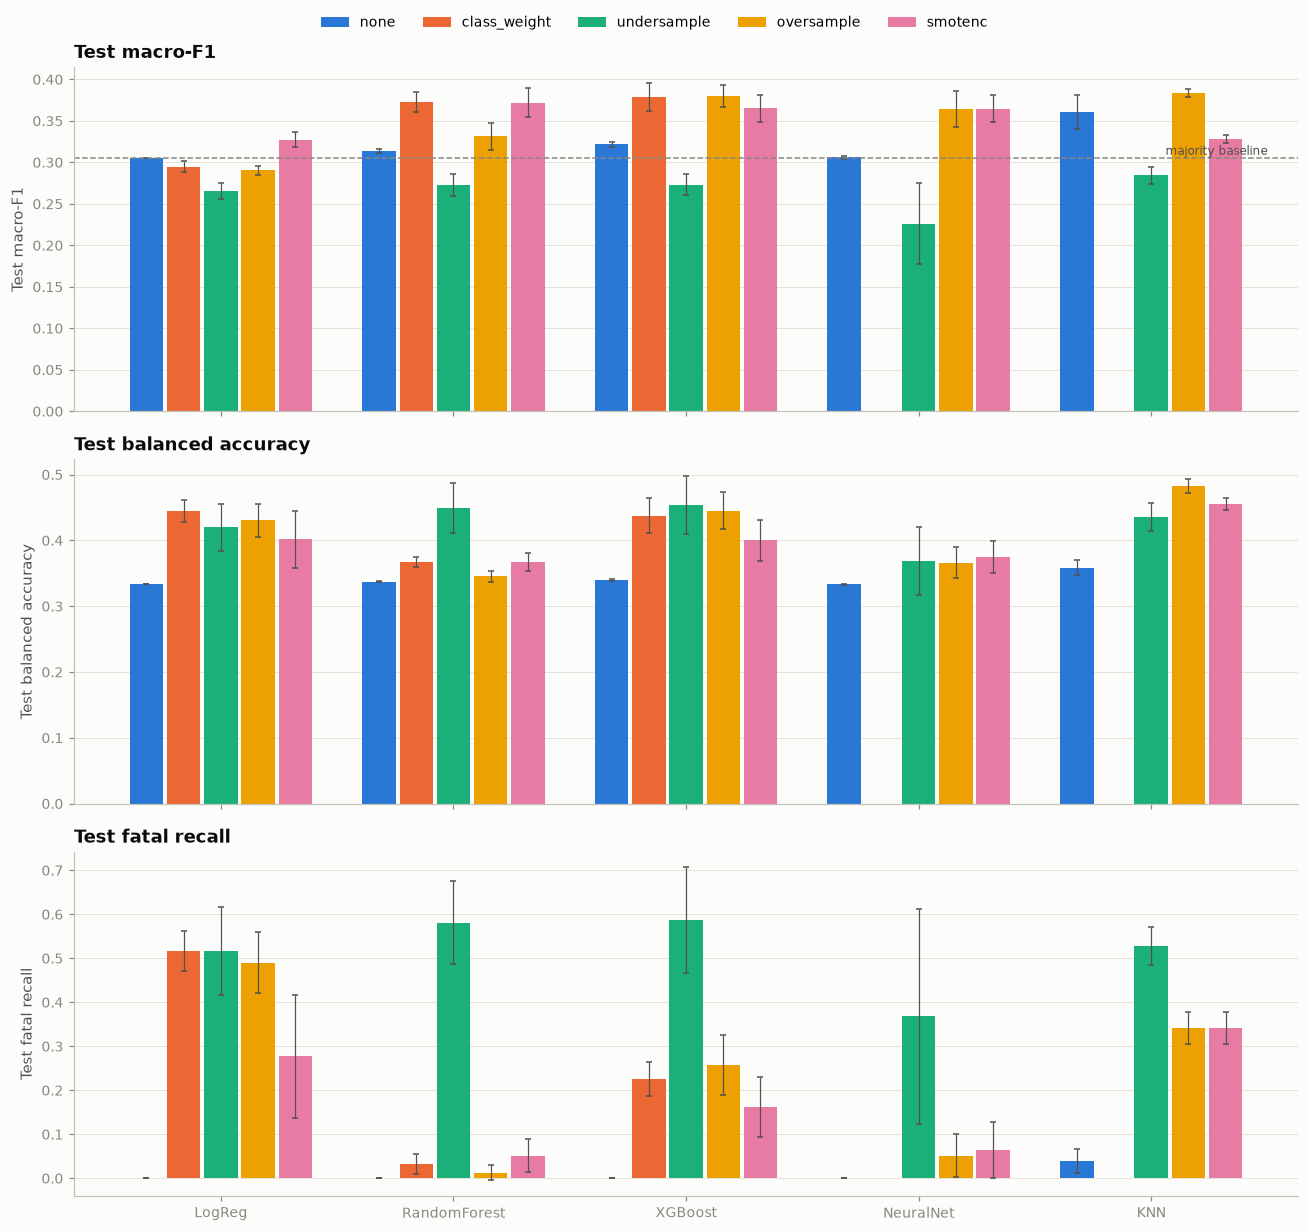

In [14]:
model_order = [m for m in MODELS if m != "Majority"]
plot_df = resA[resA["model"] != "Majority"]
majority_f1 = resA.loc[resA["model"] == "Majority", "test_macro_f1"].mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
for ax, (metric, label) in zip(axes, [("test_macro_f1", "Test macro-F1"),
                                      ("test_balanced_accuracy", "Test balanced accuracy"),
                                      ("test_fatal_recall", "Test fatal recall")]):
    grouped_bars(ax, plot_df, "model", "method", metric, series_order=IMBALANCE_METHODS,
                 x_order=model_order, ylabel=label, title=label)
axes[0].axhline(majority_f1, color=MUTED, ls="--", lw=1)
axes[0].text(len(model_order) - 0.5, majority_f1, " majority baseline", va="bottom", ha="right", fontsize=8, color=INK_2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(IMBALANCE_METHODS), bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
save_fig(fig, "11_imbalance_methods")
plt.show()

### 4.3 Recall vs precision trade-off for the Fatal class
Each point is one model + technique (mean over seeds). **Up and to the right is better.** The dashed line is the precision of random guessing (1.3%).

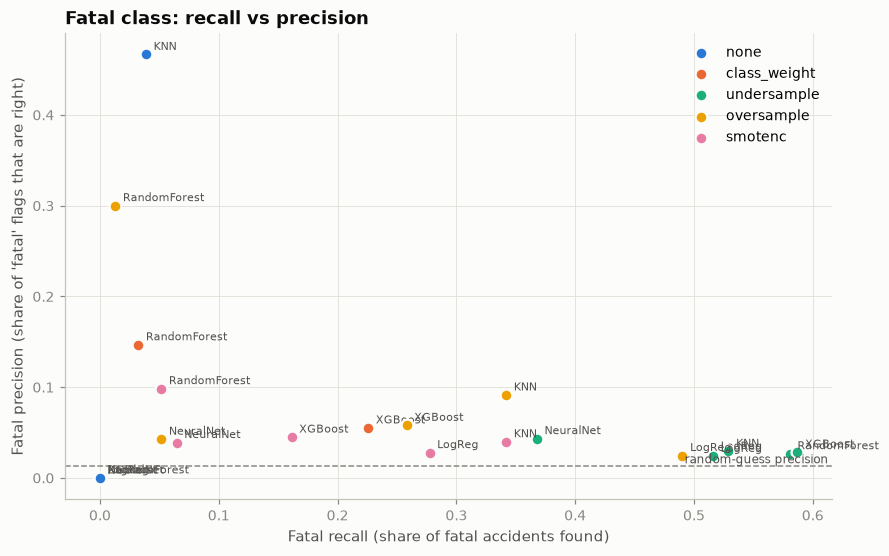

In [15]:
pts = plot_df.groupby(["model", "method"], sort=False)[["test_fatal_recall", "test_fatal_precision"]].mean().reset_index()
fatal_rate = (data[TARGET] == 2).mean()

fig, ax = plt.subplots(figsize=(9, 5.5))
for i, meth in enumerate(IMBALANCE_METHODS):
    d = pts[pts["method"] == meth]
    ax.scatter(d["test_fatal_recall"], d["test_fatal_precision"], s=60, color=SERIES[i], label=meth,
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
    for _, r in d.iterrows():
        ax.annotate(r["model"], (r["test_fatal_recall"], r["test_fatal_precision"]), xytext=(5, 3),
                    textcoords="offset points", fontsize=7.5, color=INK_2)
ax.axhline(fatal_rate, color=MUTED, ls="--", lw=1)
ax.text(ax.get_xlim()[1], fatal_rate, "random-guess precision ", ha="right", va="bottom", fontsize=8, color=INK_2)
ax.set_xlabel("Fatal recall (share of fatal accidents found)")
ax.set_ylabel("Fatal precision (share of 'fatal' flags that are right)")
ax.set_title("Fatal class: recall vs precision", loc="left")
ax.legend(loc="upper right")
save_fig(fig, "12_fatal_recall_precision")
plt.show()

### 4.4 Best technique per model
For each model, the technique with the highest mean **test macro-F1**, compared with `none`.

In [16]:
sel = (resA[resA["model"] != "Majority"]
       .groupby(["model", "method"], sort=False)[[SELECTION_METRIC, "test_balanced_accuracy",
                                                  "test_fatal_recall", "test_serious_recall", "gap_macro_f1"]]
       .mean().reset_index())
best_rows = sel.loc[sel.groupby("model", sort=False)[SELECTION_METRIC].idxmax()].set_index("model")
none_rows = sel[sel["method"] == "none"].set_index("model")

BEST_METHOD = {m: best_rows.loc[m, "method"] for m in model_order}
BEST_METHOD.update(METHOD_OVERRIDE)

summary = pd.DataFrame({
    "best_method":            [BEST_METHOD[m] for m in model_order],
    "macro_f1 (none)":        none_rows.loc[model_order, SELECTION_METRIC].values,
    "macro_f1 (best)":        [sel[(sel.model == m) & (sel.method == BEST_METHOD[m])][SELECTION_METRIC].item() for m in model_order],
    "fatal_recall (none)":    none_rows.loc[model_order, "test_fatal_recall"].values,
    "fatal_recall (best)":    [sel[(sel.model == m) & (sel.method == BEST_METHOD[m])]["test_fatal_recall"].item() for m in model_order],
    "serious_recall (best)":  [sel[(sel.model == m) & (sel.method == BEST_METHOD[m])]["test_serious_recall"].item() for m in model_order],
    "overfit_gap (best)":     [sel[(sel.model == m) & (sel.method == BEST_METHOD[m])]["gap_macro_f1"].item() for m in model_order],
}, index=pd.Index(model_order, name="model")).round(3)
summary

,best_method,macro_f1 (none),macro_f1 (best),fatal_recall (none),fatal_recall (best),serious_recall (best),overfit_gap (best)
model,,,,,,,
LogReg,smotenc,0.305,0.327,0.000,0.277,0.310,0.017
RandomForest,class_weight,0.314,0.373,0.000,0.032,0.101,0.627
XGBoost,oversample,0.322,0.380,0.000,0.258,0.367,0.246
NeuralNet,oversample,0.306,0.365,0.000,0.052,0.191,0.601
KNN,oversample,0.361,0.383,0.039,0.342,0.481,0.260


> **Caveat:** choosing the "best" technique by its test score introduces a small optimistic bias. It is acceptable for comparing techniques, but final model selection and tuning (notebook 05) must use cross-validation on the training data, with a locked test set.

### 4.5 Confusion matrices: before vs after, for the best model

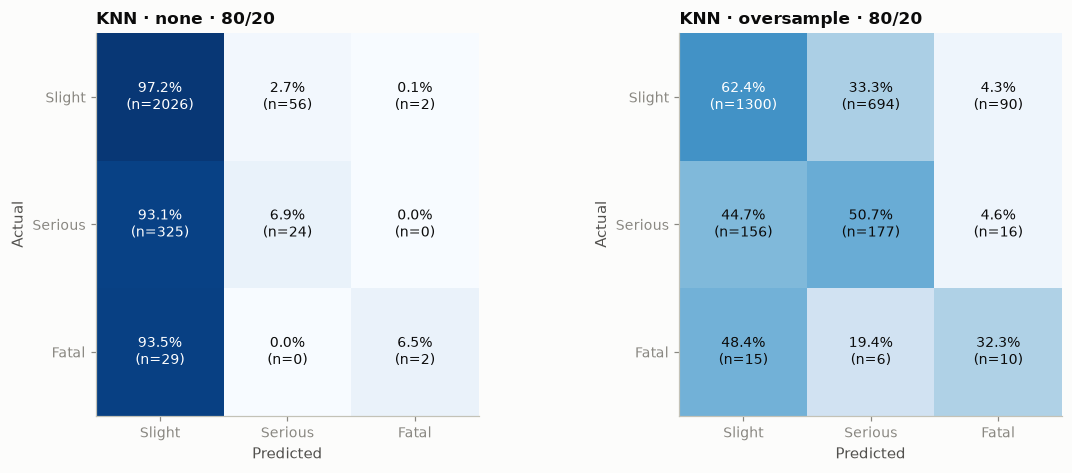

In [17]:
top_model = summary["macro_f1 (best)"].idxmax()
X_tr, X_te, y_tr, y_te = train_test_split(data[ALL_FEATURES], data[TARGET], test_size=TEST_SIZES[0],
                                          stratify=data[TARGET], random_state=RANDOM_SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, meth in zip(axes, ["none", BEST_METHOD[top_model]]):
    pipe = make_pipeline(ALL_FEATURES, top_model, meth, RANDOM_SEED)
    pipe.fit(X_tr, y_tr, **fit_params(top_model, meth, y_tr))
    plot_confusion(ax, y_te, pipe.predict(X_te), f"{top_model} · {meth} · {split_label(TEST_SIZES[0])}")
fig.tight_layout()
save_fig(fig, "13_confusion_before_after")
plt.show()

## 5. Section B: which features are really needed?
Each model now uses **its own best technique** from Section A. For each feature set we report the **paired Δ macro-F1** against `all_17`, computed on the same seeds:

> **Δ = macro-F1(all_17) − macro-F1(feature set)**: positive means removing those features **hurts**, ≈ 0 means they are not needed, negative means removing them **helps**.

In [18]:
COMBOS_B = [(m, BEST_METHOD[m]) for m in model_order]
print("Model -> technique:", dict(COMBOS_B))
resB = run_grid(FEATURE_SETS, TEST_SIZES, N_REPEATS, COMBOS_B)

Model -> technique: {'LogReg': 'smotenc', 'RandomForest': 'class_weight', 'XGBoost': 'oversample', 'NeuralNet': 'oversample', 'KNN': 'oversample'}


  done  all_17                         80/20  × 5 seeds   (   68s)


  done  without_lanes_alignment        80/20  × 5 seeds   (  137s)


  done  without_weak_road              80/20  × 5 seeds   (  202s)


  done  without_redundant_time         80/20  × 5 seeds   (  272s)


  done  reduced_11                     80/20  × 5 seeds   (  341s)


In [19]:
mean_std_table(resB, ["feature_set", "model"],
               ["n_features", "train_macro_f1", "test_macro_f1", "test_balanced_accuracy",
                "test_serious_recall", "test_fatal_recall", "test_fatal_precision"])

n_features train_macro_f1  test_macro_f1 test_balanced_accuracy test_serious_recall test_fatal_recall test_fatal_precision
feature_set             model                                                                                                                                       
all_17                  LogReg        17.000 ± 0.000  0.345 ± 0.005  0.327 ± 0.009          0.402 ± 0.044       0.310 ± 0.041     0.277 ± 0.140        0.028 ± 0.011
                        RandomForest  17.000 ± 0.000  1.000 ± 0.000  0.373 ± 0.012          0.368 ± 0.008       0.101 ± 0.010     0.032 ± 0.023        0.147 ± 0.084
                        XGBoost       17.000 ± 0.000  0.626 ± 0.010  0.380 ± 0.013          0.445 ± 0.028       0.367 ± 0.021     0.258 ± 0.068        0.058 ± 0.015
                        NeuralNet     17.000 ± 0.000  0.966 ± 0.011  0.365 ± 0.022          0.366 ± 0.024       0.191 ± 0.037     0.052 ± 0.049        0.043 ± 0.035
                        KNN           17.000 ± 0.000  0.643 ± 0.002  0.383 ± 0.005          0.482 ± 0.010       0.481 ± 0.016     0.342 ± 0.037        0.091 ± 0.011
without_lanes_alignment LogReg        15.000 ± 0.000  0.328 ± 0.006  0.311 ± 0.009          0.388 ± 0.029       0.327 ± 0.032     0.277 ± 0.078        0.022 ± 0.005
                        RandomForest  15.000 ± 0.000  0.999 ± 0.000  0.393 ± 0.024          0.380 ± 0.017       0.140 ± 0.019     0.045 ± 0.037        0.200 ± 0.117
                        XGBoost       15.000 ± 0.000  0.610 ± 0.009  0.374 ± 0.010          0.438 ± 0.021       0.368 ± 0.015     0.245 ± 0.059        0.056 ± 0.013
                        NeuralNet     15.000 ± 0.000  0.960 ± 0.009  0.368 ± 0.023          0.373 ± 0.026       0.209 ± 0.035     0.071 ± 0.058        0.051 ± 0.042
                        KNN           15.000 ± 0.000  0.647 ± 0.006  0.392 ± 0.010          0.497 ± 0.017       0.484 ± 0.030     0.374 ± 0.029        0.100 ± 0.009
without_weak_road       LogReg        13.000 ± 0.000  0.324 ± 0.005  0.308 ± 0.007          0.381 ± 0.025       0.322 ± 0.025     0.265 ± 0.074        0.020 ± 0.005
                        RandomForest  13.000 ± 0.000  0.998 ± 0.001  0.389 ± 0.017          0.377 ± 0.011       0.130 ± 0.016     0.052 ± 0.037        0.228 ± 0.137
                        XGBoost       13.000 ± 0.000  0.605 ± 0.010  0.368 ± 0.013          0.424 ± 0.027       0.367 ± 0.014     0.206 ± 0.074        0.044 ± 0.015
                        NeuralNet     13.000 ± 0.000  0.953 ± 0.006  0.360 ± 0.012          0.363 ± 0.013       0.205 ± 0.025     0.052 ± 0.043        0.041 ± 0.032
                        KNN           13.000 ± 0.000  0.641 ± 0.003  0.378 ± 0.013          0.472 ± 0.022       0.462 ± 0.029     0.329 ± 0.053        0.087 ± 0.014
without_redundant_time  LogReg        15.000 ± 0.000  0.340 ± 0.005  0.322 ± 0.012          0.397 ± 0.037       0.306 ± 0.051     0.277 ± 0.096        0.026 ± 0.008
                        RandomForest  15.000 ± 0.000  1.000 ± 0.000  0.352 ± 0.016          0.355 ± 0.009       0.074 ± 0.012     0.013 ± 0.018        0.167 ± 0.236
                        XGBoost       15.000 ± 0.000  0.619 ± 0.006  0.375 ± 0.011          0.433 ± 0.020       0.364 ± 0.027     0.226 ± 0.040        0.051 ± 0.013
                        NeuralNet     15.000 ± 0.000  0.965 ± 0.008  0.361 ± 0.015          0.364 ± 0.015       0.212 ± 0.015     0.045 ± 0.037        0.036 ± 0.026
                        KNN           15.000 ± 0.000  0.648 ± 0.003  0.371 ± 0.007          0.440 ± 0.012       0.460 ± 0.021     0.219 ± 0.027        0.066 ± 0.007
reduced_11              LogReg        11.000 ± 0.000  0.322 ± 0.005  0.309 ± 0.013          0.385 ± 0.038       0.342 ± 0.041     0.265 ± 0.087        0.020 ± 0.006
                        RandomForest  11.000 ± 0.000  0.998 ± 0.001  0.378 ± 0.013          0.369 ± 0.008       0.115 ± 0.026     0.039 ± 0.027        0.259 ± 0.199
                        XGBoost       11.000 ± 0.000  0.597 ± 0.011  0.365 ± 0.009

In [20]:
deltaB = paired_delta(resB, REFERENCE_SET)
deltaB["hurts"] = deltaB["mean"] > HURT_THRESHOLD_SD * deltaB["std"]
deltaB.round(4)

mean     std  hurts
feature_set             model                              
without_lanes_alignment LogReg        0.0160  0.0068   True
                        RandomForest -0.0195  0.0212  False
                        XGBoost       0.0056  0.0069  False
                        NeuralNet    -0.0040  0.0349  False
                        KNN          -0.0083  0.0094  False
without_weak_road       LogReg        0.0190  0.0069   True
                        RandomForest -0.0160  0.0186  False
                        XGBoost       0.0120  0.0096   True
                        NeuralNet     0.0043  0.0241  False
                        KNN           0.0052  0.0108  False
without_redundant_time  LogReg        0.0048  0.0060  False
                        RandomForest  0.0209  0.0173   True
                        XGBoost       0.0051  0.0075  False
                        NeuralNet     0.0031  0.0324  False
                        KNN           0.0120  0.0077   True
reduced_11              LogReg        0.0182  0.0100   True
                        RandomForest -0.0050  0.0202  False
                        XGBoost       0.0153  0.0070   True
                        NeuralNet     0.0032  0.0205  False
                        KNN           0.0247  0.0117   True

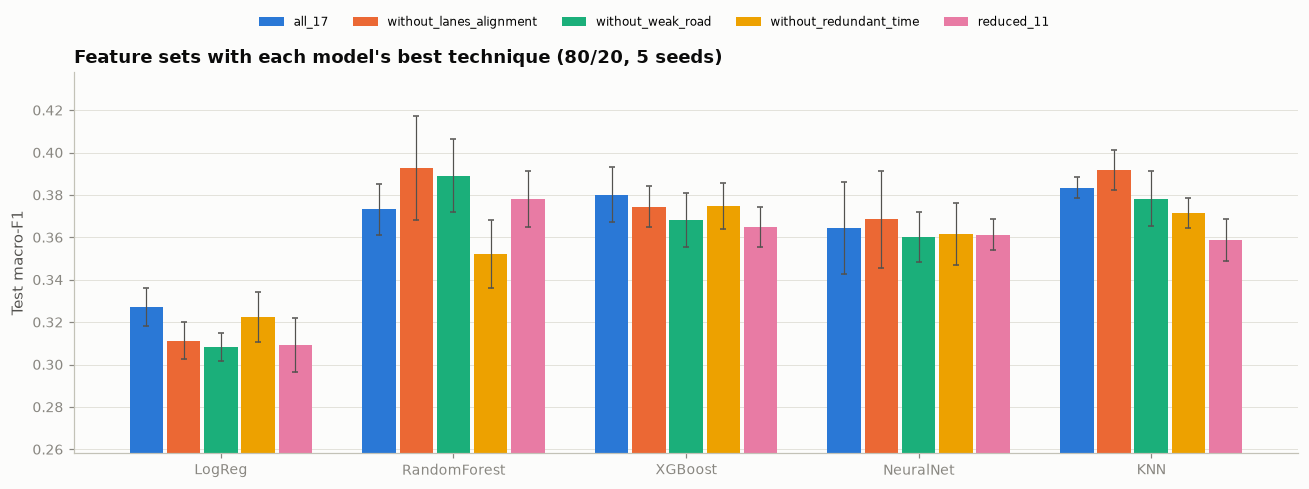

In [21]:
fig, ax = plt.subplots(figsize=(12, 4.2))
grouped_bars(ax, resB, "model", "feature_set", "test_macro_f1", series_order=list(FEATURE_SETS),
             x_order=model_order, ylabel="Test macro-F1",
             title=f"Feature sets with each model's best technique ({split_label(TEST_SIZES[0])}, {N_REPEATS} seeds)")
lo = resB.groupby(["model", "feature_set"])["test_macro_f1"].mean().min()
ax.set_ylim(max(0, lo - 0.05), None)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(FEATURE_SETS), bbox_to_anchor=(0.5, 1.06), fontsize=8)
fig.tight_layout()
save_fig(fig, "14_feature_sets_balanced")
plt.show()

*The y-axis starts above zero here so the small differences between feature sets are visible. Compare bar heights relative to each other, not to zero.*

## 6. Section C: drop-one-feature analysis (with imbalance handling)
The same test as notebook 03 §7, but now the models actually use the minority classes, so the result is meaningful. Δ > 0 means the feature is useful.

In [22]:
ablation_sets = {REFERENCE_SET: FEATURE_SETS[REFERENCE_SET]}
ablation_sets.update({f"drop: {f}": [x for x in ALL_FEATURES if x != f] for f in ALL_FEATURES})
COMBOS_C = [(m, BEST_METHOD[m]) for m in ABLATION_MODELS]
print("Model -> technique:", dict(COMBOS_C))
resC = run_grid(ablation_sets, [TEST_SIZES[0]], N_REPEATS, COMBOS_C)

deltaC = paired_delta(resC, REFERENCE_SET).reset_index()
deltaC["feature"] = deltaC["feature_set"].str.replace("drop: ", "", regex=False)
deltaC_wide = deltaC.pivot(index="feature", columns="model", values=["mean", "std"]).swaplevel(axis=1).sort_index(axis=1)
deltaC_wide = deltaC_wide.reindex(deltaC_wide[(ABLATION_MODELS[0], "mean")].sort_values(ascending=False).index)
deltaC_wide.round(4)

Model -> technique: {'LogReg': 'smotenc', 'XGBoost': 'oversample'}


  done  all_17                         80/20  × 5 seeds   (   20s)


  done  drop: hour                     80/20  × 5 seeds   (   40s)


  done  drop: time_of_day              80/20  × 5 seeds   (   59s)


  done  drop: is_night                 80/20  × 5 seeds   (   79s)


  done  drop: Day_of_week              80/20  × 5 seeds   (   99s)


... (10 outputs left out)

  done  drop: Driving_experience       80/20  × 5 seeds   (  310s)


  done  drop: Type_of_vehicle          80/20  × 5 seeds   (  329s)


  done  drop: Cause_of_accident        80/20  × 5 seeds   (  349s)


model                    LogReg         XGBoost        
                           mean     std    mean     std
feature                                                
Types_of_Junction        0.0131  0.0042  0.0076  0.0099
Age_band_of_driver       0.0094  0.0080  0.0072  0.0071
Lanes_or_Medians         0.0087  0.0045 -0.0020  0.0074
Type_of_vehicle          0.0071  0.0035  0.0010  0.0071
Weather_conditions       0.0069  0.0065  0.0054  0.0096
Road_surface_conditions  0.0051  0.0051  0.0017  0.0059
Driving_experience       0.0050  0.0048 -0.0060  0.0082
Road_alignment           0.0050  0.0060  0.0033  0.0043
Area_accident_occurred   0.0050  0.0059 -0.0028  0.0084
is_night                 0.0047  0.0046  0.0009  0.0044
Cause_of_accident        0.0045  0.0030 -0.0040  0.0131
time_of_day              0.0035  0.0072  0.0031  0.0053
is_weekend               0.0028  0.0066 -0.0040  0.0083
Day_of_week              0.0027  0.0075  0.0103  0.0064
Light_conditions         0.0001  0.0060  0.0055  0.0063
Road_surface_type       -0.0009  0.0043 -0.0017  0.0054
hour                    -0.0047  0.0059  0.0221  0.0129

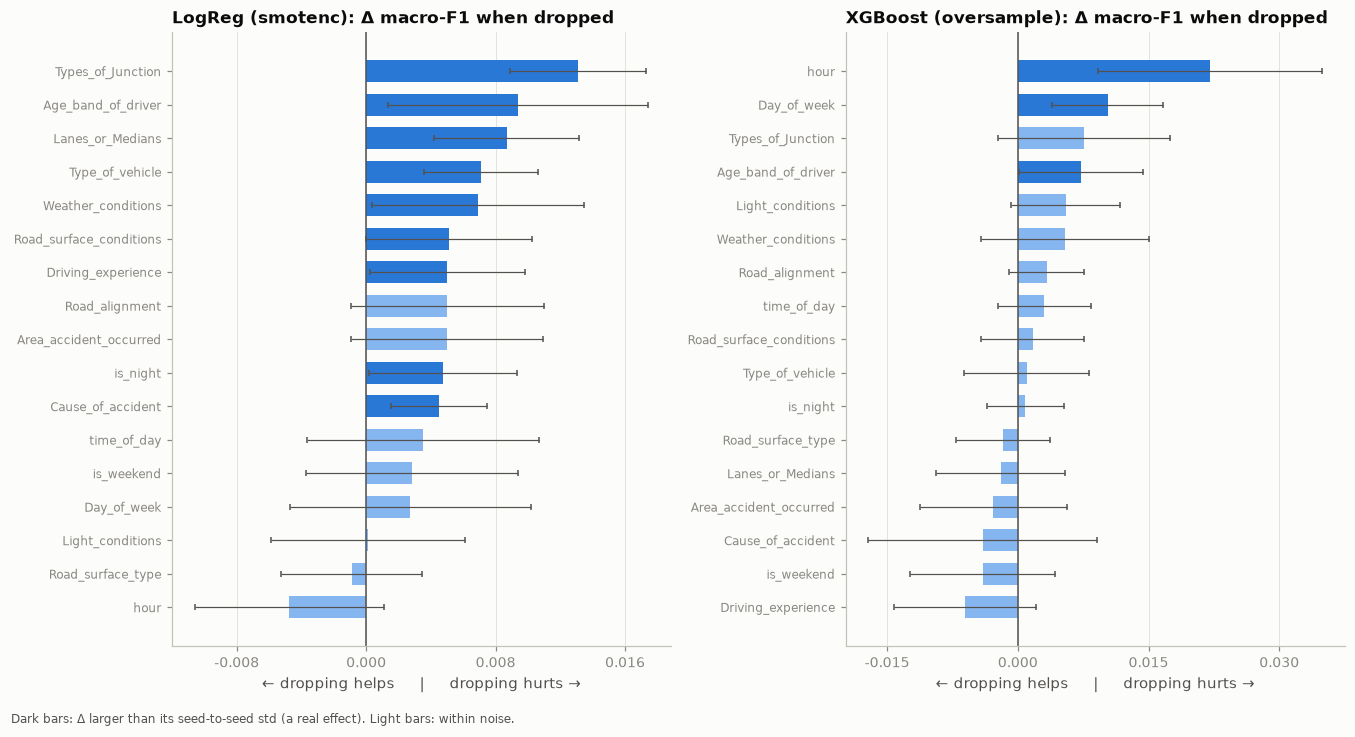

In [23]:
fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(6.2 * len(ABLATION_MODELS), 6.5), squeeze=False)
for ax, m in zip(axes[0], ABLATION_MODELS):
    d = deltaC_wide[m].sort_values("mean")
    colors = [SERIES[0] if v > s else "#86b6ef" for v, s in zip(d["mean"], d["std"])]
    ax.barh(d.index, d["mean"], xerr=d["std"], color=colors, height=0.65,
            error_kw=dict(ecolor=INK_2, lw=0.8, capsize=2))
    ax.axvline(0, color=INK_2, lw=1)
    ax.set_title(f"{m} ({BEST_METHOD[m]}): Δ macro-F1 when dropped", loc="left", fontsize=11)
    ax.set_xlabel("← dropping helps     |     dropping hurts →")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.3f"))
fig.text(0.01, -0.02, "Dark bars: Δ larger than its seed-to-seed std (a real effect). Light bars: within noise.",
         fontsize=8, color=INK_2)
fig.tight_layout()
save_fig(fig, "15_drop_one_balanced")
plt.show()

## 7. Section D: decision
**Rule:** a feature set is **acceptable** if removing its features does not *hurt* any model, i.e. no model's mean Δ macro-F1 exceeds `HURT_THRESHOLD_SD` × its std. Among acceptable sets, the **smallest** one wins, because fewer inputs means a simpler officer form and a simpler model. Ties are broken by the higher mean macro-F1.

In [24]:
hurt_any = deltaB.groupby(level="feature_set")["hurts"].any()
mean_f1 = resB.groupby("feature_set")["test_macro_f1"].mean()
decision = pd.DataFrame({
    "n_features":       {fs: len(FEATURE_SETS[fs]) for fs in FEATURE_SETS},
    "mean_test_macro_f1": mean_f1,
    "hurts_some_model": hurt_any.reindex(list(FEATURE_SETS), fill_value=False),
}).loc[list(FEATURE_SETS)]
decision["acceptable"] = ~decision["hurts_some_model"].astype(bool)
acceptable = decision[decision["acceptable"]].sort_values(["n_features", "mean_test_macro_f1"], ascending=[True, False])
FINAL_SET = acceptable.index[0]
FINAL_FEATURES = FEATURE_SETS[FINAL_SET]
REMOVED = [f for f in ALL_FEATURES if f not in FINAL_FEATURES]

print(decision.round(4), "\n")
print(f"Chosen feature set : {FINAL_SET}  ({len(FINAL_FEATURES)} features)")
print(f"Removed            : {REMOVED if REMOVED else 'nothing'}")
print(f"Technique per model: {BEST_METHOD}")

                         n_features  mean_test_macro_f1  hurts_some_model  acceptable
all_17                           17              0.3657             False        True
without_lanes_alignment          15              0.3677              True       False
without_weak_road                13              0.3608              True       False
without_redundant_time           15              0.3565              True       False
reduced_11                       11              0.3544              True       False 

Chosen feature set : all_17  (17 features)
Removed            : nothing
Technique per model: {'LogReg': 'smotenc', 'RandomForest': 'class_weight', 'XGBoost': 'oversample', 'NeuralNet': 'oversample', 'KNN': 'oversample'}


In [25]:
decision_record = {
    "decided_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "source_notebook": "04_imbalance_handling.ipynb",
    "feature_set": FINAL_SET,
    "features": FINAL_FEATURES,
    "categorical_features": [f for f in FINAL_FEATURES if f in CATEGORICAL_FEATURES],
    "numeric_features": [f for f in FINAL_FEATURES if f in NUMERIC_FEATURES],
    "removed_features": REMOVED,
    "imbalance_method_per_model": BEST_METHOD,
    "selection_metric": SELECTION_METRIC,
    "split": [split_label(t) for t in TEST_SIZES],
    "n_repeats": N_REPEATS,
    "random_seed": RANDOM_SEED,
    "decision_rule": f"smallest feature set whose removal does not reduce any model's mean test macro-F1 "
                     f"by more than {HURT_THRESHOLD_SD} std (paired over seeds)",
    "evidence_delta_macro_f1": {fs: {m: {"mean": round(float(r["mean"]), 4), "std": round(float(r["std"]), 4)}
                                     for m, r in deltaB.loc[fs].iterrows()}
                                for fs in deltaB.index.get_level_values(0).unique()},
}

# A copy in reports/ is tracked by git (data/ is not)
(EXPERIMENT_DIR / "model1_decision.json").write_text(json.dumps(decision_record, indent=2))
print("saved", (EXPERIMENT_DIR / "model1_decision.json").relative_to(PROJECT_ROOT))

if UPDATE_METADATA:
    meta["model1_final"] = decision_record          # `model1_features` (all 17) is kept for history
    META_PATH.write_text(json.dumps(meta, indent=2))
    print("updated", META_PATH.relative_to(PROJECT_ROOT), "-> key 'model1_final'")

saved reports/experiments/model1_decision.json
updated data/processed/preprocessing_metadata.json -> key 'model1_final'


## 8. Findings

*Numbers below are from the default configuration (80/20, 5 seeds, all 17 features unless stated). All are mean values on the **test** split.*

### 1. Imbalance handling works: every model now finds Serious and Fatal accidents
| Model | Best technique | Macro-F1 (none → best) | Fatal recall (none → best) | Serious recall (best) | Fatal precision (best) |
|---|---|---|---|---|---|
| KNN | oversample | 0.361 → **0.383** | 0.04 → **0.34** | 0.48 | **0.091** |
| XGBoost | oversample | 0.322 → **0.380** | 0.00 → 0.26 | 0.37 | 0.058 |
| RandomForest | class_weight | 0.314 → 0.373 | 0.00 → 0.03 | 0.10 | 0.147 |
| NeuralNet | oversample | 0.306 → 0.365 | 0.00 → 0.05 | 0.19 | 0.043 |
| LogReg | smotenc | 0.305 → 0.327 | 0.00 → 0.28 | 0.31 | 0.028 |

- Every model now beats the majority baseline on macro-F1 (0.305), apart from a few weak combinations (§4.1).
- **KNN + oversampling is the best all-rounder:** it finds about 1 in 3 fatal accidents and about half of the serious ones. Its fatal precision of 0.091 is about **7× better than random guessing** (0.013).
- **Accuracy drops (0.85 → 0.60–0.67), and that is expected.** The models stop answering "Slight" every time, so some Slight accidents are now flagged as more severe. Accuracy was never the right metric here.

### 2. The recall vs precision trade-off is the central result
- **Undersampling** gives the highest fatal recall (RandomForest/XGBoost about 0.58), but it trains on only 381 rows. Accuracy falls to about 0.40 and fatal precision to about 0.03, so most of its "fatal" flags are wrong.
- **LogReg + class_weight** reaches fatal recall 0.52 at precision 0.026 and accuracy 0.45. That is almost exactly the POC's LogReg result (0.45 / 0.018 / 0.40), which confirms the POC used class weighting.
- No technique gives high fatal recall *and* useful precision at the same time. With only 127 fatal training cases and weak features (notebook 01: Cramér's V ≤ 0.07), **this is a limit of the data, not of the method**. It should be reported as such (Research Challenge 1).
- **The selection metric matters.** Macro-F1 chose `class_weight` for RandomForest, which reaches fatal recall of only 0.03. Optimising for balanced accuracy or fatal recall would pick undersampling instead. Which one is "right" depends on how the Honor Score uses the prediction (see *Open decisions*).

### 3. SMOTENC is not better than simple oversampling here
- SMOTENC was best only for LogReg. For XGBoost, KNN and NeuralNet, plain random oversampling matched or beat it.
- A likely reason is that 15 of 17 features are categorical, so SMOTENC can only interpolate `hour`. The categorical values of a synthetic row are copied from its neighbours, which makes it close to plain duplication anyway.
- This contrasts with the common assumption (and the sample Kaggle notebook) that SMOTE is the default answer, and is worth a sentence in the thesis.

### 4. Overfitting is still the main weakness, so tuning is needed (notebook 05)
- RandomForest still scores train macro-F1 **1.000** (gap 0.63). NeuralNet + oversample scores 0.966 (gap 0.60), because oversampling repeats each fatal row about 66 times and lets it memorise them.
- XGBoost (gap 0.25) and KNN (gap 0.26) overfit less. LogReg barely overfits (0.02) but underfits.
- Limiting tree depth, increasing minimum leaf size, larger `n_neighbors` and NeuralNet regularisation are the obvious tuning targets.

### 5. Features: keep all 17. `Lanes_or_Medians` and `Road_alignment` stay
The notebook 03 assumption is **reversed** now that the models use the minority classes:

| Removing… | Effect (paired Δ macro-F1, positive = removal hurts) |
|---|---|
| Lanes + alignment | **Hurts LogReg** (+0.016 ± 0.007). RF/KNN/NeuralNet are slightly better without them, but within noise |
| Weak road group (4 features) | **Hurts LogReg** (+0.019) and **XGBoost** (+0.012) |
| Redundant time (`time_of_day`, `is_night`) | **Hurts RandomForest** (+0.021) and **KNN** (+0.012). The explicit time bands help them even though `hour` exists |
| All 6 (reduced_11) | Hurts LogReg, XGBoost and KNN |

- **Decision rule result:** every reduced set hurts at least one model beyond noise, so **all 17 features are kept**. This is recorded in `preprocessing_metadata.json` under `model1_final` and in `reports/experiments/model1_decision.json`.
- **Drop-one (Section C):**
  - For **XGBoost**, `hour` is clearly the most useful feature (+0.022), followed by `Day_of_week` and `Age_band_of_driver`. This matches notebook 01.
  - For **LogReg**, `Types_of_Junction`, `Age_band_of_driver`, `Lanes_or_Medians` and `Type_of_vehicle` matter most.
  - No single feature dominates. Severity depends on many weak signals combined.
- *Judgement call:* removing Lanes/alignment hurts **only LogReg**, the weakest model. If LogReg is dropped from consideration later, those two could be removed with no loss.

### Open decisions before notebook 05 (tuning)
1. **Which metric defines "best"?** Macro-F1 (balanced overall), or fatal/serious recall (catch dangerous cases, accept false alarms)? For a penalty system, a false "fatal-risk" flag means a harsher penalty for a driver, so precision has an ethical cost too (Chapter 4).
2. **Which models go forward to tuning?** Recommendation: **XGBoost, KNN and RandomForest**, each with its best technique. NeuralNet overfits heavily, and LogReg underfits.
3. **Use predicted probabilities instead of hard classes.** Model 2 (Honor Score) could use P(Serious) + P(Fatal) as a risk score, which avoids choosing a single threshold. This can be evaluated with PR-AUC in notebook 05.